### Importando as Bibliotecas

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)

def drop_reset_index(df):
    df = df.dropna()
    df = df.reset_index(drop=True)
    df.index += 1
    return df

### Importando a Base de Dados

In [ ]:
df = pd.read_csv("https://github.com/futpythontrader/YouTube/raw/main/Luke/Bases_de_Dados/Base_FutPythonPunter.csv")

In [ ]:
columns = ['Date','League','Home','Away','Season','Goals_H','Goals_A',
           'Odd_H','Odd_D','Odd_A','Odd_Over25','Odd_Under25','Odd_BTTS_Yes','Odd_BTTS_No',
           'Goals_Minutes_Home','Goals_Minutes_Away']
df = df[columns]
df = drop_reset_index(df)

### Análise Exploratória dos Dados

In [ ]:
df.head()

,Date,League,Home,Away,Season,Goals_H,Goals_A,Odd_H,Odd_D,Odd_A,Odd_Over25,Odd_Under25,Odd_BTTS_Yes,Odd_BTTS_No,Goals_Minutes_Home,Goals_Minutes_Away
1,2019-01-19,BOLIVIA - DIVISION PROFESIONAL,Sport Boys,Always Ready,2019,1,1,1.61,4.20,4.50,1.47,2.60,1.50,2.50,[45],[65]
2,2019-01-19,BOLIVIA - DIVISION PROFESIONAL,Real Potosi,Guabira,2019,3,1,1.57,3.80,5.00,1.53,2.40,1.57,2.25,"[20, 49, 82]",[37]
3,2019-01-19,BOLIVIA - DIVISION PROFESIONAL,The Strongest,Aurora,2019,2,1,1.18,6.50,10.00,1.30,3.50,1.72,2.00,"[15, 83]",[69]
4,2019-01-20,BOLIVIA - DIVISION PROFESIONAL,Destroyers,Blooming,2019,1,0,2.87,3.30,2.25,1.85,1.95,1.66,2.10,[45],[]
5,2019-01-20,BOLIVIA - DIVISION PROFESIONAL,San Jose,Nacional Potosi,2019,2,2,1.44,4.75,5.25,1.33,3.40,1.44,2.62,"[30, 88]","[37, 82]"


In [ ]:
df.tail()

,Date,League,Home,Away,Season,Goals_H,Goals_A,Odd_H,Odd_D,Odd_A,Odd_Over25,Odd_Under25,Odd_BTTS_Yes,Odd_BTTS_No,Goals_Minutes_Home,Goals_Minutes_Away
110765,2024-04-13,GERMANY - 2. BUNDESLIGA,Holstein Kiel,VfL Osnabruck,2023/2024,4,0,1.40,5.00,7.00,1.40,2.88,1.62,2.20,"[9, 38, 76, 84]",[]
110766,2024-04-13,GERMANY - 2. BUNDESLIGA,Paderborn,Karlsruher SC,2023/2024,1,1,2.25,3.75,3.00,1.50,2.50,1.44,2.63,[21],[26]
110767,2024-04-13,GERMANY - 2. BUNDESLIGA,Wehen,Dusseldorf,2023/2024,0,2,3.60,3.80,1.91,1.57,2.35,1.50,2.50,[],"[13, 64]"
110768,2024-04-13,WALES - CYMRU PREMIER,Haverfordwest,Colwyn Bay,2023/2024,3,1,1.57,4.00,5.10,1.75,2.02,1.78,1.93,"[8, 10, 73]",[90]
110769,2024-04-13,SPAIN - LALIGA,Atl. Madrid,Girona,2023/2024,3,1,1.85,3.75,4.00,1.65,2.20,1.57,2.25,"[34, 45, 50]",[4]


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110769 entries, 1 to 110769
Data columns (total 16 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   Date                110769 non-null  object 
 1   League              110769 non-null  object 
 2   Home                110769 non-null  object 
 3   Away                110769 non-null  object 
 4   Season              110769 non-null  object 
 5   Goals_H             110769 non-null  int64  
 6   Goals_A             110769 non-null  int64  
 7   Odd_H               110769 non-null  float64
 8   Odd_D               110769 non-null  float64
 9   Odd_A               110769 non-null  float64
 10  Odd_Over25          110769 non-null  float64
 11  Odd_Under25         110769 non-null  float64
 12  Odd_BTTS_Yes        110769 non-null  float64
 13  Odd_BTTS_No         110769 non-null  float64
 14  Goals_Minutes_Home  110769 non-null  object 
 15  Goals_Minutes_Away  110769 non-nul

In [ ]:
df.describe()

,Goals_H,Goals_A,Odd_H,Odd_D,Odd_A,Odd_Over25,Odd_Under25,Odd_BTTS_Yes,Odd_BTTS_No
count,110769.000000,110769.000000,110769.000000,110769.000000,110769.000000,110769.000000,110769.000000,110769.000000,110769.000000
mean,1.456057,1.161227,2.556682,3.646865,3.931139,1.967345,1.887139,1.865755,1.869566
std,1.268480,1.133135,1.738610,1.090412,3.139268,0.413554,0.483596,0.340618,0.350216
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,0.000000,1.750000,3.200000,2.400000,1.710000,1.610000,1.700000,1.700000
50%,1.000000,1.000000,2.200000,3.400000,3.200000,1.980000,1.800000,1.850000,1.830000
75%,2.000000,2.000000,2.850000,3.800000,4.500000,2.200000,2.070000,2.020000,2.000000
max,18.000000,12.000000,67.000000,26.000000,292.000000,4.330000,13.000000,11.000000,4.970000


### Operações Básicas com o Pandas (Criação de Variáveis)

##### Probabilidades

In [ ]:
df['p_H'] = 1 / df['Odd_H']
df['p_D'] = 1 / df['Odd_D']
df['p_A'] = 1 / df['Odd_A']

##### Coeficiente de Variação das Odds do Match Odds

In [ ]:
desvio_padrao = df[['Odd_H','Odd_D','Odd_A']].std(axis=1)
media = df[['Odd_H','Odd_D','Odd_A']].mean(axis=1)
CV_Odds = desvio_padrao / media
df['CV_Odds'] = CV_Odds

##### Média de Pontos (PPG)

In [ ]:
n_per = 5

In [ ]:
df['Ptos_H'] = np.where(df['Goals_H'] >  df['Goals_A'], 3,
               np.where(df['Goals_H'] == df['Goals_A'], 1, 0))


df['Ptos_A'] = np.where(df['Goals_H'] > df['Goals_A'], 0,
               np.where(df['Goals_H'] == df['Goals_A'], 1, 3))

df['Media_Ptos_H'] = df.groupby('Home')['Ptos_H'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_Ptos_A'] = df.groupby('Away')['Ptos_A'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_Ptos_H'] = df.groupby('Home')['Media_Ptos_H'].shift(1)
df['Media_Ptos_A'] = df.groupby('Away')['Media_Ptos_A'].shift(1)

df['DesvPad_Ptos_H'] = df.groupby('Home')['Ptos_H'].rolling(window=n_per, min_periods=n_per).std().reset_index(0,drop=True)
df['DesvPad_Ptos_A'] = df.groupby('Away')['Ptos_A'].rolling(window=n_per, min_periods=n_per).std().reset_index(0,drop=True)
df['DesvPad_Ptos_H'] = df.groupby('Home')['DesvPad_Ptos_H'].shift(1)
df['DesvPad_Ptos_A'] = df.groupby('Away')['DesvPad_Ptos_A'].shift(1)

df['CV_Ptos_H'] = df['DesvPad_Ptos_H'] / df['Media_Ptos_H']
df['CV_Ptos_A'] = df['DesvPad_Ptos_A'] / df['Media_Ptos_A']

##### Média Gols Marcados

In [ ]:
df['Media_GM_H'] = df.groupby('Home')['Goals_H'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_GM_A'] = df.groupby('Away')['Goals_A'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_GM_H'] = df.groupby('Home')['Media_GM_H'].shift(1)
df['Media_GM_A'] = df.groupby('Away')['Media_GM_A'].shift(1)

df['DesvPad_GM_H'] = df.groupby('Home')['Goals_H'].rolling(window=n_per, min_periods=n_per).std().reset_index(0,drop=True)
df['DesvPad_GM_A'] = df.groupby('Away')['Goals_A'].rolling(window=n_per, min_periods=n_per).std().reset_index(0,drop=True)
df['DesvPad_GM_H'] = df.groupby('Home')['DesvPad_GM_H'].shift(1)
df['DesvPad_GM_A'] = df.groupby('Away')['DesvPad_GM_A'].shift(1)

df['CV_GM_H'] = df['DesvPad_GM_H'] / df['Media_GM_H']
df['CV_GM_A'] = df['DesvPad_GM_A'] / df['Media_GM_A']

##### Média de Gols Sofridos

In [ ]:
df['Media_GS_H'] = df.groupby('Home')['Goals_A'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_GS_A'] = df.groupby('Away')['Goals_H'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_GS_H'] = df.groupby('Home')['Media_GS_H'].shift(1)
df['Media_GS_A'] = df.groupby('Away')['Media_GS_A'].shift(1)

df['DesvPad_GS_H'] = df.groupby('Home')['Goals_A'].rolling(window=n_per, min_periods=n_per).std().reset_index(0,drop=True)
df['DesvPad_GS_A'] = df.groupby('Away')['Goals_H'].rolling(window=n_per, min_periods=n_per).std().reset_index(0,drop=True)
df['DesvPad_GS_H'] = df.groupby('Home')['DesvPad_GS_H'].shift(1)
df['DesvPad_GS_A'] = df.groupby('Away')['DesvPad_GS_A'].shift(1)

df['CV_GS_H'] = df['DesvPad_GS_H'] / df['Media_GS_H']
df['CV_GS_A'] = df['DesvPad_GS_A'] / df['Media_GS_A']

##### Média de Saldo de Gols

In [ ]:
df['SG_H'] = df['Goals_H'] - df['Goals_A']
df['SG_A'] = df['Goals_A'] - df['Goals_H']

df['Media_SG_H'] = df.groupby('Home')['SG_H'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_SG_A'] = df.groupby('Away')['SG_A'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_SG_H'] = df.groupby('Home')['Media_SG_H'].shift(1)
df['Media_SG_A'] = df.groupby('Away')['Media_SG_A'].shift(1)

df['DesvPad_SG_H'] = df.groupby('Home')['SG_H'].rolling(window=n_per, min_periods=n_per).std().reset_index(0,drop=True)
df['DesvPad_SG_A'] = df.groupby('Away')['SG_A'].rolling(window=n_per, min_periods=n_per).std().reset_index(0,drop=True)
df['DesvPad_SG_H'] = df.groupby('Home')['DesvPad_SG_H'].shift(1)
df['DesvPad_SG_A'] = df.groupby('Away')['DesvPad_SG_A'].shift(1)

df['CV_SG_H'] = df['DesvPad_SG_H'] / df['Media_SG_H']
df['CV_SG_A'] = df['DesvPad_SG_A'] / df['Media_SG_A']

##### Média de Saldo de Gols Ponderado pela Probabilidade do Time

In [ ]:
df['SG_H_01'] = (df['Goals_H'] - df['Goals_A']) / df['p_H']
df['SG_A_01'] = (df['Goals_A'] - df['Goals_H']) / df['p_A']

df['Media_SG_H_01'] = df.groupby('Home')['SG_H_01'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_SG_A_01'] = df.groupby('Away')['SG_A_01'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_SG_H_01'] = df.groupby('Home')['Media_SG_H_01'].shift(1)
df['Media_SG_A_01'] = df.groupby('Away')['Media_SG_A_01'].shift(1)

df['DesvPad_SG_H_01'] = df.groupby('Home')['SG_H_01'].rolling(window=n_per, min_periods=n_per).std().reset_index(0,drop=True)
df['DesvPad_SG_A_01'] = df.groupby('Away')['SG_A_01'].rolling(window=n_per, min_periods=n_per).std().reset_index(0,drop=True)
df['DesvPad_SG_H_01'] = df.groupby('Home')['DesvPad_SG_H_01'].shift(1)
df['DesvPad_SG_A_01'] = df.groupby('Away')['DesvPad_SG_A_01'].shift(1)

df['CV_SG_H_01'] = df['DesvPad_SG_H_01'] / df['Media_SG_H_01']
df['CV_SG_A_01'] = df['DesvPad_SG_A_01'] / df['Media_SG_A_01']

##### Média de Saldo de Gols Ponderado pela Probabilidade do Adversário

In [ ]:
df['SG_H_02'] = (df['Goals_H'] - df['Goals_A']) / df['p_A']
df['SG_A_02'] = (df['Goals_A'] - df['Goals_H']) / df['p_H']

df['Media_SG_H_02'] = df.groupby('Home')['SG_H_02'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_SG_A_02'] = df.groupby('Away')['SG_A_02'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_SG_H_02'] = df.groupby('Home')['Media_SG_H_02'].shift(1)
df['Media_SG_A_02'] = df.groupby('Away')['Media_SG_A_02'].shift(1)

df['DesvPad_SG_H_02'] = df.groupby('Home')['SG_H_02'].rolling(window=n_per, min_periods=n_per).std().reset_index(0,drop=True)
df['DesvPad_SG_A_02'] = df.groupby('Away')['SG_A_02'].rolling(window=n_per, min_periods=n_per).std().reset_index(0,drop=True)
df['DesvPad_SG_H_02'] = df.groupby('Home')['DesvPad_SG_H_02'].shift(1)
df['DesvPad_SG_A_02'] = df.groupby('Away')['DesvPad_SG_A_02'].shift(1)

df['CV_SG_H_02'] = df['DesvPad_SG_H_02'] / df['Media_SG_H_02']
df['CV_SG_A_02'] = df['DesvPad_SG_A_02'] / df['Media_SG_A_02']

##### Média do Valor do Gol

In [ ]:
df['VG_H'] = df['Goals_H'] * df['p_A']
df['VG_A'] = df['Goals_A'] * df['p_H']

df['Media_VG_H'] = df.groupby('Home')['VG_H'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_VG_A'] = df.groupby('Away')['VG_A'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_VG_H'] = df.groupby('Home')['Media_VG_H'].shift(1)
df['Media_VG_A'] = df.groupby('Away')['Media_VG_A'].shift(1)

df['DesvPad_VG_H'] = df.groupby('Home')['VG_H'].rolling(window=n_per, min_periods=n_per).std().reset_index(0,drop=True)
df['DesvPad_VG_A'] = df.groupby('Away')['VG_A'].rolling(window=n_per, min_periods=n_per).std().reset_index(0,drop=True)
df['DesvPad_VG_H'] = df.groupby('Home')['DesvPad_VG_H'].shift(1)
df['DesvPad_VG_A'] = df.groupby('Away')['DesvPad_VG_A'].shift(1)

df['CV_VG_H'] = df['DesvPad_VG_H'] / df['Media_VG_H']
df['CV_VG_A'] = df['DesvPad_VG_A'] / df['Media_VG_A']

##### Custo do Gol

In [ ]:
# Custo do Gol Original

df['CG_H_00'] = df['p_H'] / df['Goals_H']
df['CG_A_00'] = df['p_A'] / df['Goals_A']

df.replace(np.inf, 1, inplace=True)

df['Media_CG_H_00'] = df.groupby('Home')['CG_H_00'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_CG_A_00'] = df.groupby('Away')['CG_A_00'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_CG_H_00'] = df.groupby('Home')['Media_CG_H_00'].shift(1)
df['Media_CG_A_00'] = df.groupby('Away')['Media_CG_A_00'].shift(1)

df['DesvPad_CG_H_00'] = df.groupby('Home')['CG_H_00'].rolling(window=n_per, min_periods=n_per).std().reset_index(0,drop=True)
df['DesvPad_CG_A_00'] = df.groupby('Away')['CG_A_00'].rolling(window=n_per, min_periods=n_per).std().reset_index(0,drop=True)
df['DesvPad_CG_H_00'] = df.groupby('Home')['DesvPad_CG_H_00'].shift(1)
df['DesvPad_CG_A_00'] = df.groupby('Away')['DesvPad_CG_A_00'].shift(1)

df['CV_CG_H_00'] = df['DesvPad_CG_H_00'] / df['Media_CG_H_00']
df['CV_CG_A_00'] = df['DesvPad_CG_A_00'] / df['Media_CG_A_00']

In [ ]:
# Custo do Gol 1.0

df['CG_H_01'] = df['Goals_H'] / df['p_H']
df['CG_A_01'] = df['Goals_A'] / df['p_A']

df['Media_CG_H_01'] = df.groupby('Home')['CG_H_01'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_CG_A_01'] = df.groupby('Away')['CG_A_01'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_CG_H_01'] = df.groupby('Home')['Media_CG_H_01'].shift(1)
df['Media_CG_A_01'] = df.groupby('Away')['Media_CG_A_01'].shift(1)

df['DesvPad_CG_H_01'] = df.groupby('Home')['CG_H_01'].rolling(window=n_per, min_periods=n_per).std().reset_index(0,drop=True)
df['DesvPad_CG_A_01'] = df.groupby('Away')['CG_A_01'].rolling(window=n_per, min_periods=n_per).std().reset_index(0,drop=True)
df['DesvPad_CG_H_01'] = df.groupby('Home')['DesvPad_CG_H_01'].shift(1)
df['DesvPad_CG_A_01'] = df.groupby('Away')['DesvPad_CG_A_01'].shift(1)

df['CV_CG_H_01'] = df['DesvPad_CG_H_01'] / df['Media_CG_H_01']
df['CV_CG_A_01'] = df['DesvPad_CG_A_01'] / df['Media_CG_A_01']

In [ ]:
# Custo do Gol 2.0

df['CG_H_02'] = (df['Goals_H'] / 2) + (df['p_H'] / 2)
df['CG_A_02'] = (df['Goals_A'] / 2) + (df['p_A'] / 2)

df['Media_CG_H_02'] = df.groupby('Home')['CG_H_02'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_CG_A_02'] = df.groupby('Away')['CG_A_02'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_CG_H_02'] = df.groupby('Home')['Media_CG_H_02'].shift(1)
df['Media_CG_A_02'] = df.groupby('Away')['Media_CG_A_02'].shift(1)

df['DesvPad_CG_H_02'] = df.groupby('Home')['CG_H_02'].rolling(window=n_per, min_periods=n_per).std().reset_index(0,drop=True)
df['DesvPad_CG_A_02'] = df.groupby('Away')['CG_A_02'].rolling(window=n_per, min_periods=n_per).std().reset_index(0,drop=True)
df['DesvPad_CG_H_02'] = df.groupby('Home')['DesvPad_CG_H_02'].shift(1)
df['DesvPad_CG_A_02'] = df.groupby('Away')['DesvPad_CG_A_02'].shift(1)

df['CV_CG_H_02'] = df['DesvPad_CG_H_02'] / df['Media_CG_H_02']
df['CV_CG_A_02'] = df['DesvPad_CG_A_02'] / df['Media_CG_A_02']

##### Variáveis Obtidas das Odds

In [ ]:
# Proporção entre as Odds
df['H_D'] = df['Odd_H'] / df['Odd_D']
df['H_A'] = df['Odd_H'] / df['Odd_A']
df['D_H'] = df['Odd_D'] / df['Odd_H']
df['D_A'] = df['Odd_D'] / df['Odd_A']
df['A_H'] = df['Odd_A'] / df['Odd_H']
df['A_D'] = df['Odd_A'] / df['Odd_D']

# Diferença Absoluta entre as Odds
df['DifAbs_HomeAway'] = np.abs(df['Odd_H'] - df['Odd_A'])
df['DifAbs_HomeDraw'] = np.abs(df['Odd_H'] - df['Odd_D'])
df['DifAbs_DrawAway'] = np.abs(df['Odd_D'] - df['Odd_A'])

# Angulo de Disparidade entre as Odds
df['Angle_HomeAway'] = np.degrees(np.arctan((df['Odd_A'] - df['Odd_H']) / 2))
df['Angle_HomeDraw'] = np.degrees(np.arctan((df['Odd_D'] - df['Odd_H']) / 2))
df['Angle_DrawAway'] = np.degrees(np.arctan((df['Odd_A'] - df['Odd_D']) / 2))

# Diferenças Percentuais entre as Odds
df['DifPer_HomeAway'] = np.abs((df['Odd_H'] - df['Odd_A'])) / df['Odd_A']
df['DifPer_HomeDraw'] = np.abs((df['Odd_H'] - df['Odd_D'])) / df['Odd_D']
df['DifPer_DrawAway'] = np.abs((df['Odd_D'] - df['Odd_A'])) / df['Odd_A']

In [ ]:
colunas_deletar = ['Ptos_H','Ptos_A','DesvPad_Ptos_H','DesvPad_Ptos_A',
                   'DesvPad_GM_H','DesvPad_GM_A',
                   'DesvPad_GS_H','DesvPad_GS_A',
                   'SG_H','SG_A','DesvPad_SG_H','DesvPad_SG_A',
                   'SG_H_01','SG_A_01','DesvPad_SG_H_01','DesvPad_SG_A_01',
                   'SG_H_02','SG_A_02','DesvPad_SG_H_02','DesvPad_SG_A_02',
                   'VG_H','VG_A','DesvPad_VG_H','DesvPad_VG_A',
                   'CG_H_00','CG_A_00','DesvPad_CG_H_00','DesvPad_CG_A_00',
                   'CG_H_01','CG_A_01','DesvPad_CG_H_01','DesvPad_CG_A_01',
                   'CG_H_02','CG_A_02','DesvPad_CG_H_02','DesvPad_CG_A_02']

df = df.drop(colunas_deletar, axis=1)

In [ ]:
df = drop_reset_index(df)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85670 entries, 1 to 85670
Data columns (total 75 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Date                85670 non-null  object 
 1   League              85670 non-null  object 
 2   Home                85670 non-null  object 
 3   Away                85670 non-null  object 
 4   Season              85670 non-null  object 
 5   Goals_H             85670 non-null  int64  
 6   Goals_A             85670 non-null  int64  
 7   Odd_H               85670 non-null  float64
 8   Odd_D               85670 non-null  float64
 9   Odd_A               85670 non-null  float64
 10  Odd_Over25          85670 non-null  float64
 11  Odd_Under25         85670 non-null  float64
 12  Odd_BTTS_Yes        85670 non-null  float64
 13  Odd_BTTS_No         85670 non-null  float64
 14  Goals_Minutes_Home  85670 non-null  object 
 15  Goals_Minutes_Away  85670 non-null  object 
 16  p_H 

In [ ]:
display(df)

,Date,League,Home,Away,Season,Goals_H,Goals_A,Odd_H,Odd_D,Odd_A,Odd_Over25,Odd_Under25,Odd_BTTS_Yes,Odd_BTTS_No,Goals_Minutes_Home,Goals_Minutes_Away,p_H,p_D,p_A,CV_Odds,Media_Ptos_H,Media_Ptos_A,CV_Ptos_H,CV_Ptos_A,Media_GM_H,Media_GM_A,CV_GM_H,CV_GM_A,Media_GS_H,Media_GS_A,CV_GS_H,CV_GS_A,Media_SG_H,Media_SG_A,CV_SG_H,CV_SG_A,Media_SG_H_01,Media_SG_A_01,CV_SG_H_01,CV_SG_A_01,Media_SG_H_02,Media_SG_A_02,CV_SG_H_02,CV_SG_A_02,Media_VG_H,Media_VG_A,CV_VG_H,CV_VG_A,Media_CG_H_00,Media_CG_A_00,CV_CG_H_00,CV_CG_A_00,Media_CG_H_01,Media_CG_A_01,CV_CG_H_01,CV_CG_A_01,Media_CG_H_02,Media_CG_A_02,CV_CG_H_02,CV_CG_A_02,H_D,H_A,D_H,D_A,A_H,A_D,DifAbs_HomeAway,DifAbs_HomeDraw,DifAbs_DrawAway,Angle_HomeAway,Angle_HomeDraw,Angle_DrawAway,DifPer_HomeAway,DifPer_HomeDraw,DifPer_DrawAway
1,2019-02-27,BOLIVIA - DIVISION PROFESIONAL,Real Potosi,Bolivar,2019,2,2,4.33,4.20,1.61,1.40,2.87,1.40,2.75,"[40, 51]","[5, 65]",0.230947,0.238095,0.621118,0.453918,2.0,1.6,0.707107,0.838525,2.0,2.2,0.500000,0.592655,1.6,1.8,0.559017,0.993808,0.4,0.4,3.791438,2.850439,-0.142,1.516,-27.354256,2.642912,3.490,0.816,1.550339,3.020884,0.437817,0.903232,0.373168,0.752472,0.338920,0.247007,0.492232,0.659290,3.424,6.014,0.368770,0.677603,1.290850,1.299099,0.427961,0.504290,1.030952,2.689441,0.969977,2.608696,0.371824,0.383333,2.72,0.13,2.59,-53.673174,-3.718994,-52.324652,1.689441,0.030952,1.608696
2,2019-03-01,BOLIVIA - DIVISION PROFESIONAL,Oriente Petrolero,Blooming,2019,0,1,2.90,3.50,2.30,1.61,2.25,1.53,2.37,[],[84],0.344828,0.285714,0.434783,0.206897,2.2,0.8,0.497930,1.629801,2.0,1.0,0.612372,1.414214,1.2,1.8,0.912871,0.464811,0.8,-0.8,1.045825,-2.404423,1.646,-5.290,1.144774,-1.810166,2.500,-1.154,0.969536,-3.124044,0.592828,0.434783,0.624590,1.414214,0.335203,0.660026,0.545514,0.706323,3.866,2.820,0.567396,1.430446,1.258330,0.649298,0.492506,1.130962,0.828571,1.260870,1.206897,1.521739,0.793103,0.657143,0.60,0.60,1.20,-16.699244,16.699244,-30.963757,0.260870,0.171429,0.521739
3,2019-03-08,PARAGUAY - PRIMERA DIVISION,San Lorenzo,Dep. Capiata,2019,0,1,2.15,3.30,3.20,1.61,2.25,1.50,2.50,[],[86],0.465116,0.303030,0.312500,0.220942,2.4,0.8,0.559017,1.629801,1.4,0.4,0.391230,2.236068,0.8,1.2,1.629801,0.912871,0.6,-0.8,2.527625,-1.854050,1.774,-5.560,2.729522,-2.014413,1.528,-1.276,2.165130,-1.702239,0.670741,0.248447,0.556300,2.236068,0.270015,0.818182,0.456085,0.496904,4.704,2.200,0.618886,2.236068,0.864052,0.310352,0.299631,1.414271,0.651515,0.671875,1.534884,1.031250,1.488372,0.969697,1.05,1.15,0.10,27.699473,29.898902,-2.862405,0.328125,0.348485,0.031250
4,2019-03-10,PARAGUAY - PRIMERA DIVISION,Deportivo Santani,Cerro Porteno,2019,1,3,3.30,3.40,2.00,2.00,1.80,1.80,1.90,[45],"[6, 40, 57]",0.303030,0.294118,0.500000,0.269319,0.6,1.4,0.912871,1.083268,0.6,1.4,0.912871,0.814411,1.0,1.2,0.707107,0.697217,-0.4,0.2,-1.369306,6.519202,-1.000,0.262,-1.376590,8.847407,-1.100,1.664,-1.372697,4.183000,0.232767,0.399221,0.950046,0.914940,0.634135,0.492846,0.536017,0.691324,1.590,2.948,0.948206,0.860777,0.510546,0.949099,0.499377,0.626492,0.970588,1.650000,1.030303,1.700000,0.606061,0.588235,1.30,0.10,1.40,-33.023868,2.862405,-34.992020,0.650000,0.029412,0.700000
5,2019-03-13,BOLIVIA - DIVISION PROFESIONAL,Oriente Petrolero,Always Ready,2019,4,1,1.50,3.80,6.00,1.61,2.25,1.72,2.00,"[8, 23, 45, 55]",[3],0.666667,0.263158,0.166667,0.597394,2.0,0.4,0.707107,1.369306,1.8,0.8,0.824022,0.559017,1.2,1.8,0.912871,0.464811,0.6,-1.0,1.900292,-1.000000,1.066,-3.112,2.589404,-1.005826,2.040,-2.640,1.535183,-1.234872,0.528312,0.450431,0.849671,0.682465,0.442180,0.435947,0.800852,0.865870,3.436,3.756,0.801321,0.751461,1.146301,0.551307,0.672393,0.433054,0.394737,0.250000,2.533333,0.633333,4.000000,1.578947,4.50,2.30,2.20,66.037511,48.990913,47.726311,0.750000,0.605263,0.366667
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,..

In [ ]:
df['Back_Home'] = np.where((df['Goals_H'] >  df['Goals_A']), 1, 0)
df['Back_Draw'] = np.where((df['Goals_H'] == df['Goals_A']), 1, 0)
df['Back_Away'] = np.where((df['Goals_H']  < df['Goals_A']), 1, 0)

df['Lay_Home'] = np.where((df['Goals_H'] <= df['Goals_A']), 1, 0)
df['Lay_Draw'] = np.where((df['Goals_H'] != df['Goals_A']), 1, 0)
df['Lay_Away'] = np.where((df['Goals_H'] >= df['Goals_A']), 1, 0)

df['Lay_0x1'] = np.where((df['Goals_H'] == 0) & (df['Goals_A'] == 1), 0, 1)
df['Lay_1x0'] = np.where((df['Goals_H'] == 1) & (df['Goals_A'] == 0), 0, 1)

df['Lay_Gol_H'] = np.where((df['Goals_H'] > df['Goals_A']) & (df['Goals_H'] >= 4), 0, 1)
df['Lay_Gol_A'] = np.where((df['Goals_A'] > df['Goals_H']) & (df['Goals_A'] >= 4), 0, 1)

df.to_excel("Base_Variáveis.xlsx", index=False)

### Calculando a Matriz de Correlação

In [ ]:
df0 = df[['Goals_H','Goals_A','p_H','p_D','p_A']]
df0

,Goals_H,Goals_A,p_H,p_D,p_A
1,2,2,0.230947,0.238095,0.621118
2,0,1,0.344828,0.285714,0.434783
3,0,1,0.465116,0.303030,0.312500
4,1,3,0.303030,0.294118,0.500000
5,4,1,0.666667,0.263158,0.166667
...,...,...,...,...,...
85666,4,0,0.714286,0.200000,0.142857
85667,1,1,0.444444,0.266667,0.333333
85668,0,2,0.277778,0.263158,0.523560
85669,3,1,0.636943,0.250000,0.196078


In [ ]:
correlacao = df0.corr()
correlacao

,Goals_H,Goals_A,p_H,p_D,p_A
Goals_H,1.000000,-0.038344,0.328981,-0.233289,-0.288478
Goals_A,-0.038344,1.000000,-0.273147,-0.038337,0.309006
p_H,0.328981,-0.273147,1.000000,-0.422657,-0.956403
p_D,-0.233289,-0.038337,-0.422657,1.000000,0.168479
p_A,-0.288478,0.309006,-0.956403,0.168479,1.000000


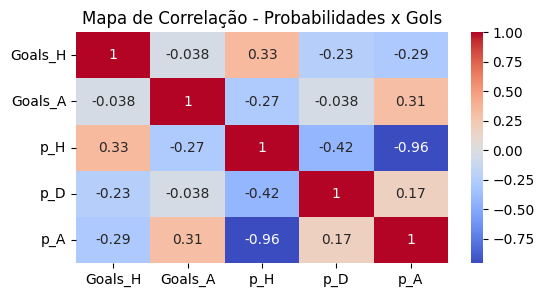

In [ ]:
plt.figure(figsize=(6,3))
sns.heatmap(correlacao, annot=True, cmap='coolwarm')
plt.title("Mapa de Correlação - Probabilidades x Gols")
plt.show()

In [ ]:
features = ['p_H','p_D','p_A','CV_Odds',
'Media_Ptos_H','Media_Ptos_A','CV_Ptos_H','CV_Ptos_A',
'Media_GM_H','Media_GM_A','CV_GM_H','CV_GM_A',
'Media_GS_H','Media_GS_A','CV_GS_H','CV_GS_A',
'Media_SG_H','Media_SG_A','CV_SG_H','CV_SG_A',
'Media_SG_H_01','Media_SG_A_01','CV_SG_H_01','CV_SG_A_01',
'Media_SG_H_02','Media_SG_A_02','CV_SG_H_02','CV_SG_A_02',
'Media_VG_H','Media_VG_A','CV_VG_H','CV_VG_A',
'Media_CG_H_00','Media_CG_A_00','CV_CG_H_00','CV_CG_A_00',
'Media_CG_H_01','Media_CG_A_01','CV_CG_H_01','CV_CG_A_01',
'Media_CG_H_02','Media_CG_A_02','CV_CG_H_02','CV_CG_A_02',
'H_D','H_A','D_H','D_A','A_H','A_D',
'DifAbs_HomeAway','DifAbs_HomeDraw','DifAbs_DrawAway',
'Angle_HomeAway','Angle_HomeDraw','Angle_DrawAway',
'DifPer_HomeAway','DifPer_HomeDraw','DifPer_DrawAway',
'Back_Home']
df0 = df[features]

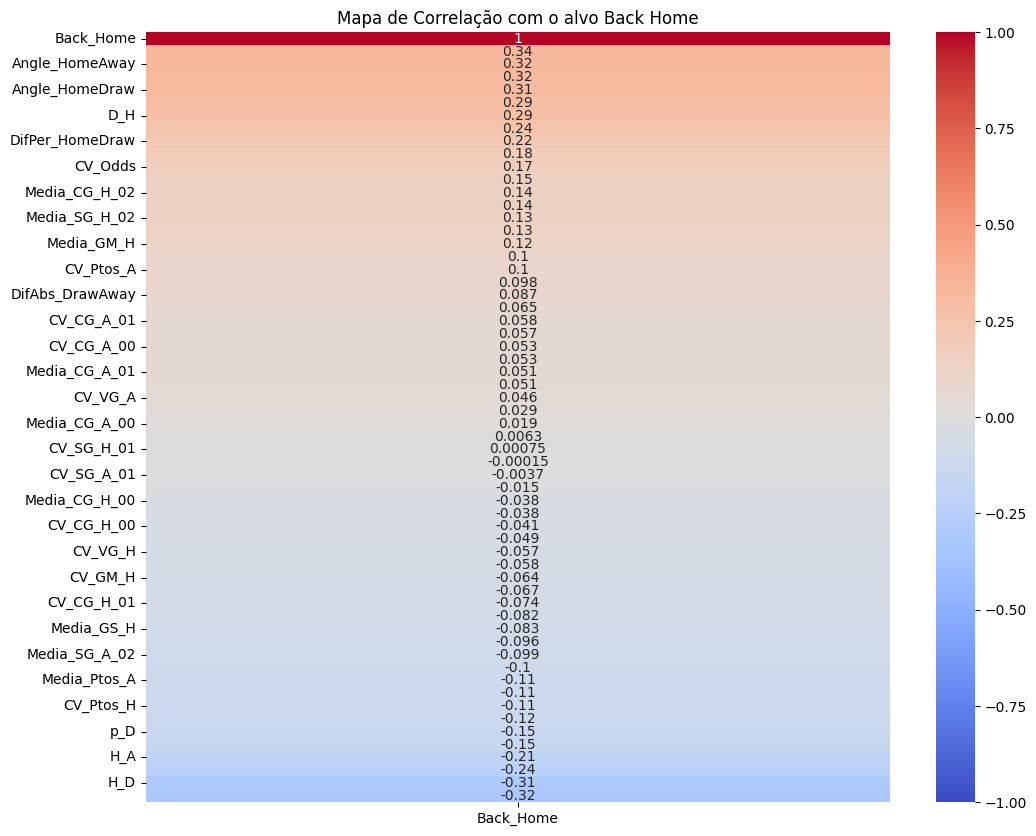

In [ ]:
correlation_matrix = df0.corr()

plt.figure(figsize=(12,10))

sns.heatmap(correlation_matrix[['Back_Home']].sort_values(by='Back_Home',
                                            ascending=False),
                                            annot=True,
                                            cmap='coolwarm',
                                            vmin=-1,
                                            vmax=1)
plt.title("Mapa de Correlação com o alvo Back Home")
plt.show()